# 14 — CNNs e transferência de aprendizado em classificação visual

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 14/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** Exemplos centrais são leves; o laboratório TensorFlow/Keras é opcional e depende de ambiente compatível.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 14/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor; teste complementar TensorFlow/Keras 2.22.0-rc0 aprovado com CNN não treinada e inferência sintética.


### Materiais complementares

- [Guia Técnico](./reference_materials/14_cnn_transfer_learning_visual.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_cnn_transfer_learning_visual.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Comparar convoluções aprendidas, baselines clássicos e inferência pré-treinada.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

CNNs aprendem filtros por retropropagação; transfer learning reutiliza representações treinadas em outro domínio. O congelamento de camadas diminui o custo inicial, mas o domínio de origem pode ser inadequado. A teoria de backpropagation e arquitetura CNN já foi desenvolvida na Disciplina 07; aqui a ênfase é no pipeline de visão e no desenho experimental.

### Conceito matemático

$$F_{out}=\sigma(K*I+b)$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.data import camera
from scipy.signal import convolve2d
img=camera().astype(float)/255
kernel=np.array([[1,0,-1],[2,0,-2],[1,0,-1]])/4
filtered=convolve2d(img,kernel,mode='same',boundary='symm')
print('Filtro de borda (fixo, não treinado):',filtered.shape,'média absoluta:',round(abs(filtered).mean(),4))

Filtro de borda (fixo, não treinado): (512, 512) média absoluta: 0.032


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

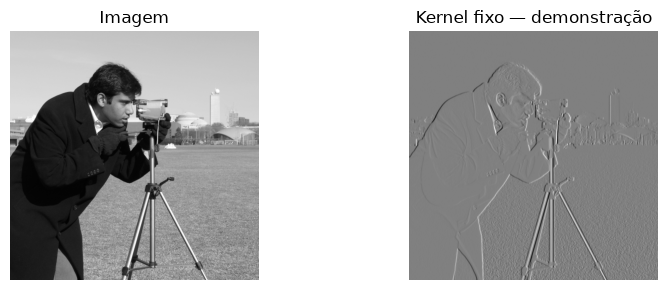

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].imshow(img,cmap='gray');ax[0].set_title('Imagem')
ax[1].imshow(filtered,cmap='gray');ax[1].set_title('Kernel fixo — demonstração')
for a in ax:a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

Este filtro fixo não é uma CNN treinada; sua função é esclarecer a operação. Treinamento com Keras fica no laboratório opcional dependente de TensorFlow.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** O que significa congelar um backbone pré-treinado?

**Resolução comentada:** Manter os pesos do extrator fixos enquanto se aprende inicialmente uma nova cabeça de classificação.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Laboratório opcional — requer dependência extra

**Não execute esta parte sem verificar a instalação e a memória disponível.** O bloco abaixo está em texto de código para consulta; pode ser copiado para uma célula nova quando o ambiente estiver preparado.

```python
# Opcional — somente com TensorFlow já instalado e recursos suficientes
import tensorflow as tf
model=tf.keras.Sequential([
 tf.keras.Input(shape=(32,32,3)),
 tf.keras.layers.Conv2D(8,3,activation='relu'),
 tf.keras.layers.MaxPooling2D(),
 tf.keras.layers.Flatten(),
 tf.keras.layers.Dense(2,activation='softmax')])
model.summary()
```

## Erros comuns e limitações

Não descarregar automaticamente ImageNet nem reutilizar imagens sem licenças conferidas.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Comparar convoluções aprendidas, baselines clássicos e inferência pré-treinada.
- **Mecanismo:** CNNs aprendem filtros por retropropagação; transfer learning reutiliza representações treinadas em outro domínio.
- **Equação:** $F_{out}=\sigma(K*I+b)$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** fine tuning e vazamento. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **fine tuning e vazamento** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **fine tuning e vazamento** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
